<a href="https://colab.research.google.com/github/dataengi44/Code1/blob/main/SWYNEX_Exploratory_Data_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!git clone https://github.com/dataengi44/SWYNEX-Data-Cleaning-Preparation.git

Cloning into 'SWYNEX-Data-Cleaning-Preparation'...
remote: Enumerating objects: 11, done.
remote: Counting objects: 100% (11/11), done.
remote: Compressing objects: 100% (8/8), done.
remote: Total 11 (delta 1), reused 11 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (11/11), 14.54 MiB | 12.50 MiB/s, done.
Resolving deltas: 100% (1/1), done.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "/content/SWYNEX-Data-Cleaning-Preparation/output/cleaned_online_retail.csv"
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (536641, 11)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TransactionType,TotalAmount,DataQualityFlag
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,Sale,15.30,Normal
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,Sale,20.34,Normal
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,Sale,22.00,Normal
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,Sale,20.34,Normal
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,Sale,20.34,Normal


In [3]:
# Dataset information
print("DATASET INFORMATION")
print("-" * 50)

df.info()

# Dataset dimensions
print("\nDataset Shape:", df.shape)

# Missing values
print("\nMISSING VALUES")
print("-" * 50)
print(df.isnull().sum())

# Duplicate records
print("\nDUPLICATE RECORDS")
print("-" * 50)
print("Total duplicates:", df.duplicated().sum())

# Statistical summary
print("\nSTATISTICAL SUMMARY")
print("-" * 50)
print(df.describe().round(2))

# Transaction types
print("\nTRANSACTION TYPES")
print("-" * 50)
print(df["TransactionType"].value_counts())

# Data quality flags
print("\nDATA QUALITY FLAGS")
print("-" * 50)
print(df["DataQualityFlag"].value_counts())

# Date range
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")

print("\nDATE RANGE")
print("Start Date:", df["InvoiceDate"].min())
print("End Date:", df["InvoiceDate"].max())

DATASET INFORMATION
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 536641 entries, 0 to 536640
Data columns (total 11 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   InvoiceNo        536641 non-null  object 
 1   StockCode        536641 non-null  object 
 2   Description      536641 non-null  object 
 3   Quantity         536641 non-null  int64  
 4   InvoiceDate      536641 non-null  object 
 5   UnitPrice        536641 non-null  float64
 6   CustomerID       401604 non-null  float64
 7   Country          536641 non-null  object 
 8   TransactionType  536641 non-null  object 
 9   TotalAmount      536641 non-null  float64
 10  DataQualityFlag  536641 non-null  object 
dtypes: float64(3), int64(1), object(7)
memory usage: 45.0+ MB

Dataset Shape: (536641, 11)

MISSING VALUES
--------------------------------------------------
InvoiceNo               0
StockCode             

In [4]:
# Convert InvoiceDate to datetime
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")

# Create a separate dataset for valid sales
sales_df = df[
    (df["TransactionType"] == "Sale") &
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0) &
    (df["TotalAmount"] > 0)
].copy()

# Extract date-related features
sales_df["Year"] = sales_df["InvoiceDate"].dt.year
sales_df["Month"] = sales_df["InvoiceDate"].dt.month
sales_df["MonthName"] = sales_df["InvoiceDate"].dt.strftime("%b")
sales_df["DayName"] = sales_df["InvoiceDate"].dt.day_name()
sales_df["Hour"] = sales_df["InvoiceDate"].dt.hour

print("Valid sales records:", len(sales_df))

# Overall sales statistics
total_revenue = sales_df["TotalAmount"].sum()
total_quantity = sales_df["Quantity"].sum()
total_orders = sales_df["InvoiceNo"].nunique()
total_customers = sales_df["CustomerID"].nunique()
total_products = sales_df["StockCode"].nunique()

print("\nOVERALL SALES PERFORMANCE")
print("-" * 40)
print("Total Revenue:", round(total_revenue, 2))
print("Total Quantity Sold:", total_quantity)
print("Total Orders:", total_orders)
print("Unique Customers:", total_customers)
print("Unique Products:", total_products)
print("Average Order Value:", round(total_revenue / total_orders, 2))

Valid sales records: 524873

OVERALL SALES PERFORMANCE
----------------------------------------
Total Revenue: 10631048.74
Total Quantity Sold: 5572415
Total Orders: 19959
Unique Customers: 4338
Unique Products: 3920
Average Order Value: 532.64


MONTHLY SALES PERFORMANCE


,Revenue,Orders,Quantity
InvoiceDate,,,
2010-12-01,821452.73,1559,358019
2011-01-01,689811.61,1086,387099
2011-02-01,522545.56,1100,282934
2011-03-01,716215.26,1454,376599
2011-04-01,536968.49,1246,307952
2011-05-01,769296.61,1681,395001
2011-06-01,760547.01,1533,388511
2011-07-01,718076.12,1475,399692
2011-08-01,746779.32,1360,421019


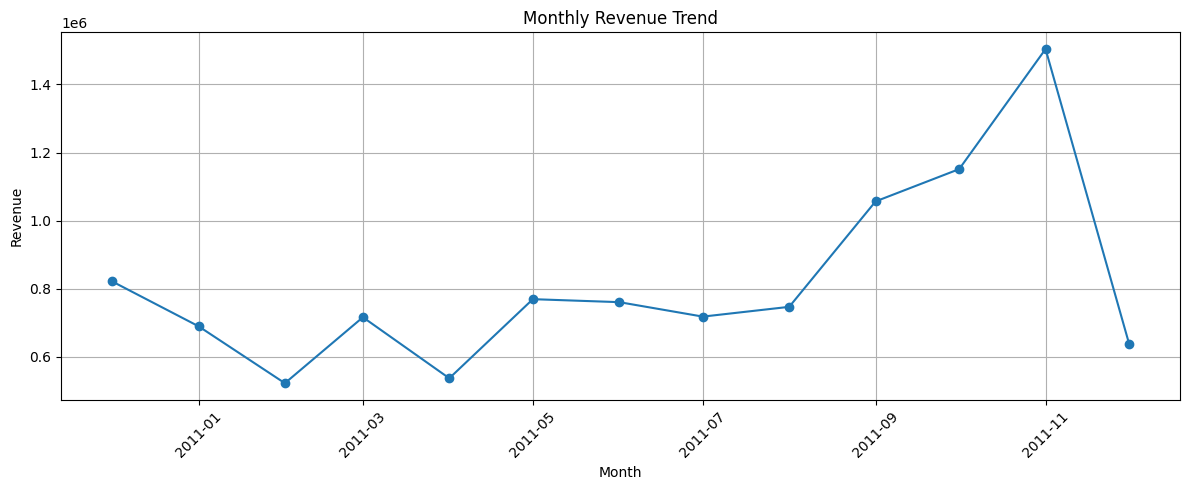

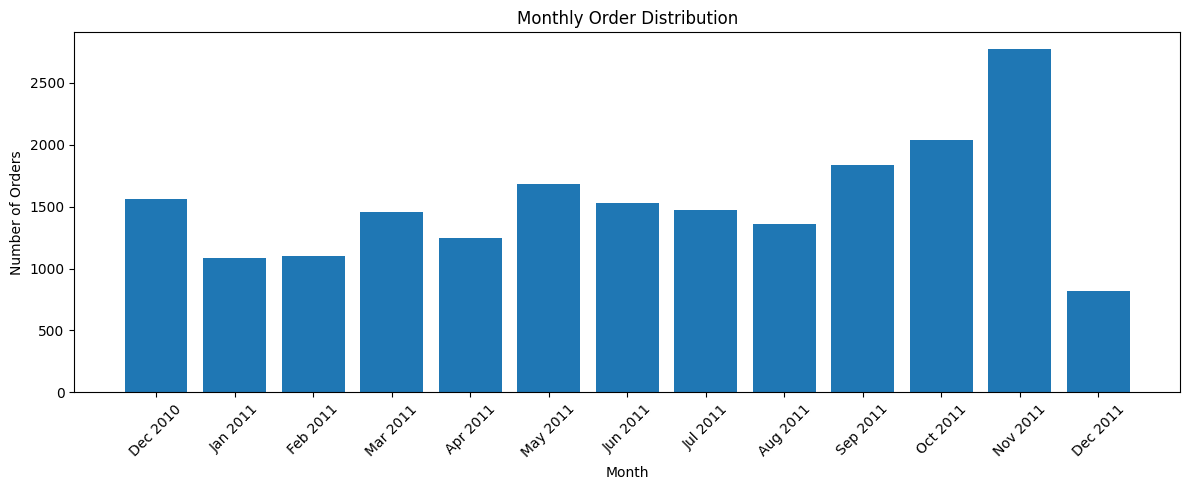

In [5]:
# Monthly sales analysis

monthly_sales = (
    sales_df
    .set_index("InvoiceDate")
    .resample("MS")
    .agg(
        Revenue=("TotalAmount", "sum"),
        Orders=("InvoiceNo", "nunique"),
        Quantity=("Quantity", "sum")
    )
)

print("MONTHLY SALES PERFORMANCE")
display(monthly_sales.round(2))

# Monthly revenue chart
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales.index,
    monthly_sales["Revenue"],
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

# Monthly orders chart
plt.figure(figsize=(12, 5))

plt.bar(
    monthly_sales.index.strftime("%b %Y"),
    monthly_sales["Orders"]
)

plt.title("Monthly Order Distribution")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

AVERAGE DAILY REVENUE BY WEEKDAY


,Revenue
DayName,
Monday,37782.60
Tuesday,41840.39
Wednesday,34850.46
Thursday,41496.09
Friday,36528.17
Saturday,NaN
Sunday,16135.82


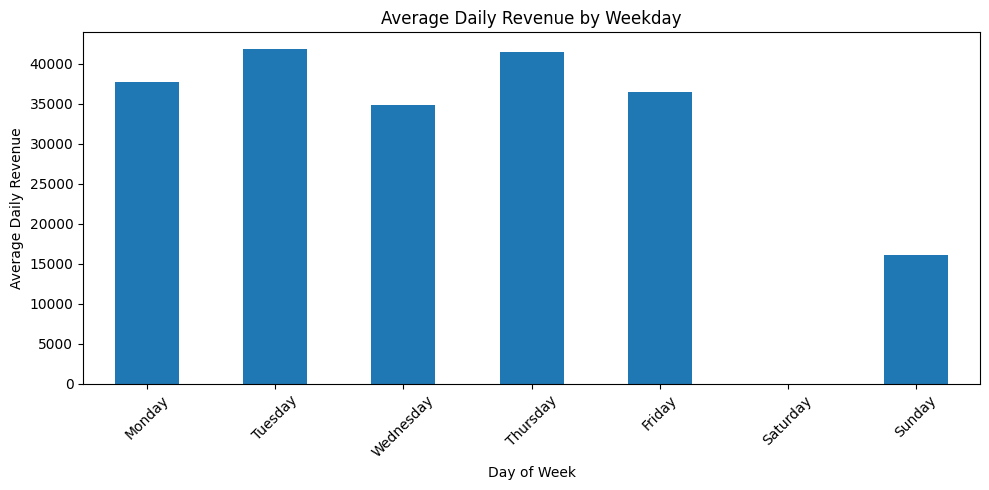

In [6]:
# Daily revenue
daily_sales = (
    sales_df
    .groupby(sales_df["InvoiceDate"].dt.date)["TotalAmount"]
    .sum()
    .reset_index(name="Revenue")
)

daily_sales["DayName"] = pd.to_datetime(
    daily_sales["InvoiceDate"]
).dt.day_name()

weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_sales = (
    daily_sales
    .groupby("DayName")["Revenue"]
    .mean()
    .reindex(weekday_order)
)

print("AVERAGE DAILY REVENUE BY WEEKDAY")
display(weekday_sales.round(2))

plt.figure(figsize=(10, 5))

weekday_sales.plot(kind="bar")

plt.title("Average Daily Revenue by Weekday")
plt.xlabel("Day of Week")
plt.ylabel("Average Daily Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

TOP 10 PRODUCTS BY REVENUE


,StockCode,Description,TotalRevenue,TotalQuantity,TotalOrders
4140,DOT,DOTCOM POSTAGE,206248.77,706,706
1338,22423,REGENCY CAKESTAND 3 TIER,174156.54,13851,1988
2659,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,1
3631,85123A,WHITE HANGING HEART T-LIGHT HOLDER,104284.24,37580,2189
2868,47566,PARTY BUNTING,99445.23,18283,1685
3610,85099B,JUMBO BAG RED RETROSPOT,94159.81,48371,2089
2115,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033,247
4142,POST,POSTAGE,78101.88,3150,1126
4141,M,Manual,77750.27,6984,289
2022,23084,RABBIT NIGHT LIGHT,66870.03,30739,994


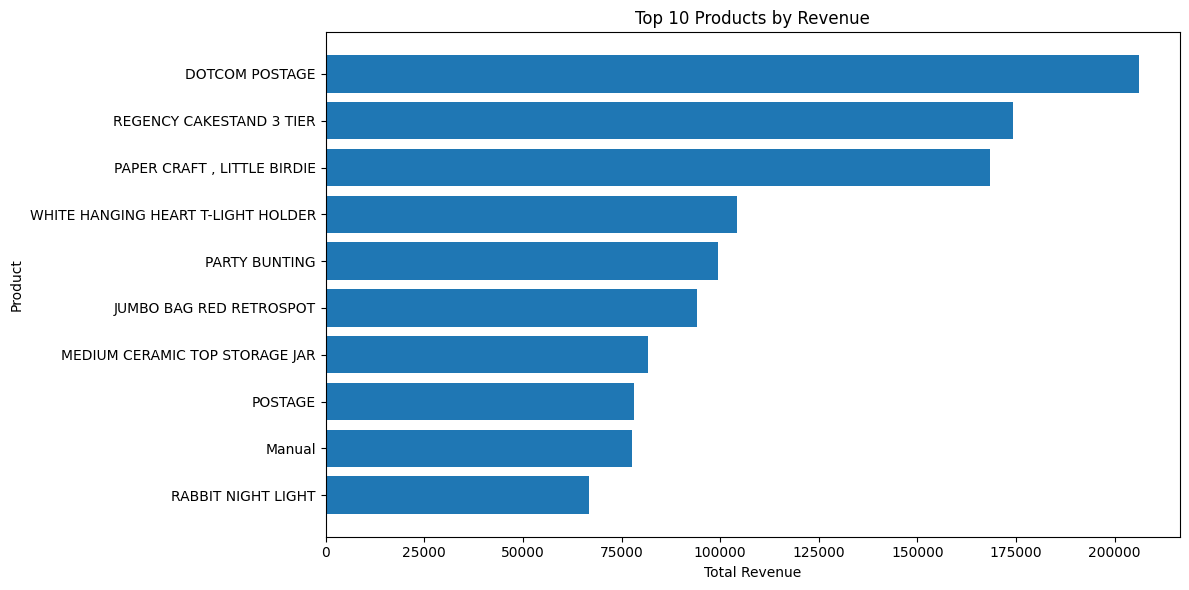

TOP 10 PRODUCTS BY QUANTITY SOLD


,StockCode,Description,TotalRevenue,TotalQuantity,TotalOrders
2659,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,1
2115,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033,247
3119,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,13814.01,54951,535
3610,85099B,JUMBO BAG RED RETROSPOT,94159.81,48371,2089
3631,85123A,WHITE HANGING HEART T-LIGHT HOLDER,104284.24,37580,2189
1128,22197,POPCORN HOLDER,34288.67,36749,803
448,21212,PACK OF 72 RETROSPOT CAKE CASES,21246.45,36396,1320
3407,84879,ASSORTED COLOUR BIRD ORNAMENT,58927.62,36362,1455
2022,23084,RABBIT NIGHT LIGHT,66870.03,30739,994
1403,22492,MINI PAINT SET VINTAGE,16937.82,26633,380


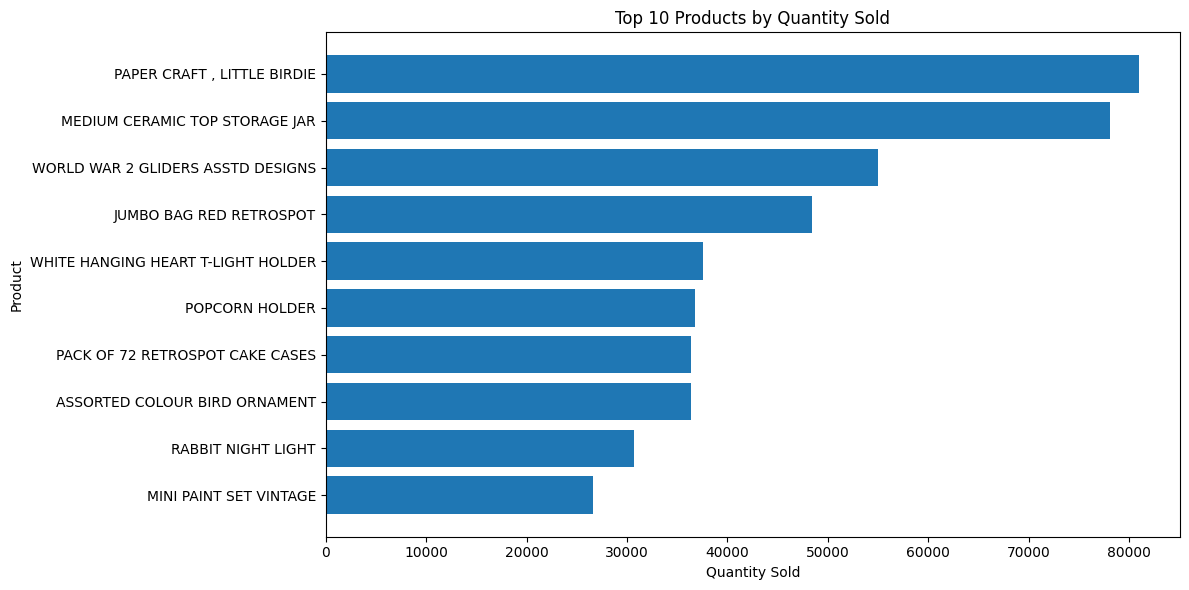

In [7]:
# Product-wise sales analysis

product_sales = (
    sales_df.groupby(["StockCode", "Description"])
    .agg(
        TotalRevenue=("TotalAmount", "sum"),
        TotalQuantity=("Quantity", "sum"),
        TotalOrders=("InvoiceNo", "nunique")
    )
    .reset_index()
)

# Top 10 products by revenue
top_revenue_products = product_sales.sort_values(
    by="TotalRevenue", ascending=False
).head(10)

print("TOP 10 PRODUCTS BY REVENUE")
display(top_revenue_products.round(2))

plt.figure(figsize=(12, 6))
plt.barh(
    top_revenue_products["Description"].iloc[::-1],
    top_revenue_products["TotalRevenue"].iloc[::-1]
)
plt.title("Top 10 Products by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

# Top 10 products by quantity
top_quantity_products = product_sales.sort_values(
    by="TotalQuantity", ascending=False
).head(10)

print("TOP 10 PRODUCTS BY QUANTITY SOLD")
display(top_quantity_products)

plt.figure(figsize=(12, 6))
plt.barh(
    top_quantity_products["Description"].iloc[::-1],
    top_quantity_products["TotalQuantity"].iloc[::-1]
)
plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Quantity Sold")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

TOP 10 COUNTRIES BY REVENUE


,Country,TotalRevenue,TotalOrders,TotalQuantity,UniqueCustomers
36,United Kingdom,8990682.03,18018,4646901,3920
24,Netherlands,285446.34,94,200361,9
10,EIRE,283140.52,288,147007,3
14,Germany,228678.40,457,119154,94
13,France,209625.37,392,112060,87
0,Australia,138453.81,57,83891,9
31,Spain,61558.56,90,27933,30
33,Switzerland,57067.60,54,30617,21
3,Belgium,41196.34,98,23237,25
32,Sweden,38367.83,36,36078,8


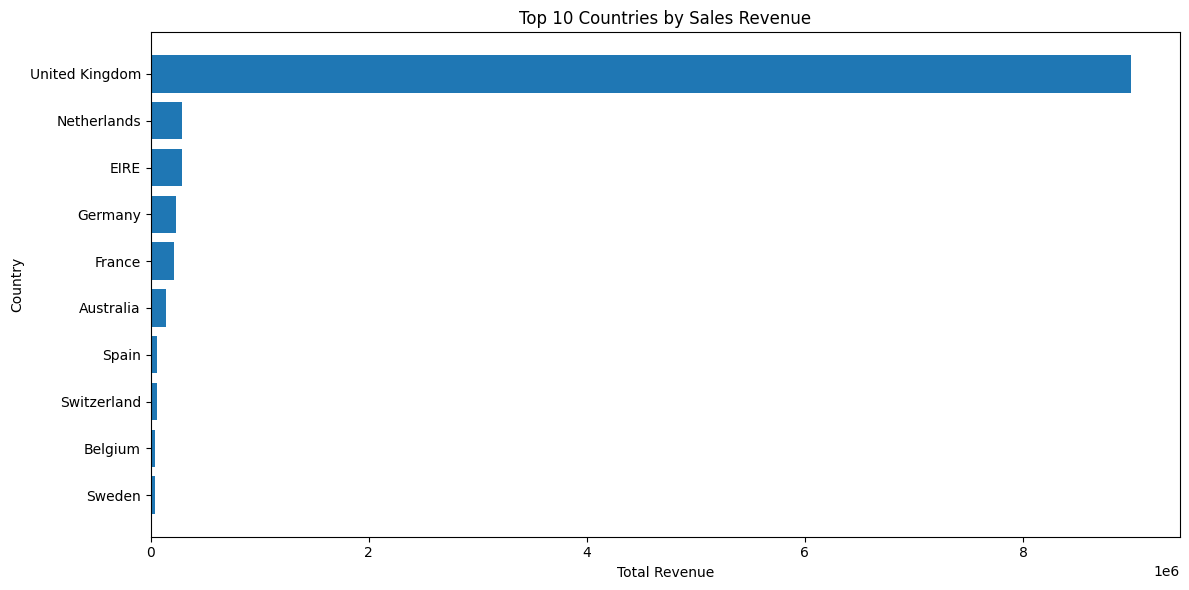

TOP 10 COUNTRIES - REVENUE CONTRIBUTION


,Country,TotalRevenue,RevenuePercentage
36,United Kingdom,8990682.03,84.57
24,Netherlands,285446.34,2.69
10,EIRE,283140.52,2.66
14,Germany,228678.40,2.15
13,France,209625.37,1.97
0,Australia,138453.81,1.30
31,Spain,61558.56,0.58
33,Switzerland,57067.60,0.54
3,Belgium,41196.34,0.39
32,Sweden,38367.83,0.36


In [8]:
# Country-wise sales analysis

country_sales = (
    sales_df.groupby("Country")
    .agg(
        TotalRevenue=("TotalAmount", "sum"),
        TotalOrders=("InvoiceNo", "nunique"),
        TotalQuantity=("Quantity", "sum"),
        UniqueCustomers=("CustomerID", "nunique")
    )
    .reset_index()
    .sort_values(by="TotalRevenue", ascending=False)
)

print("TOP 10 COUNTRIES BY REVENUE")

top_countries = country_sales.head(10)
display(top_countries.round(2))

# Country-wise revenue chart

plt.figure(figsize=(12, 6))

plt.barh(
    top_countries["Country"].iloc[::-1],
    top_countries["TotalRevenue"].iloc[::-1]
)

plt.title("Top 10 Countries by Sales Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

# Revenue contribution percentage

country_sales["RevenuePercentage"] = (
    country_sales["TotalRevenue"] / sales_df["TotalAmount"].sum()
) * 100

print("TOP 10 COUNTRIES - REVENUE CONTRIBUTION")

display(
    country_sales[
        ["Country", "TotalRevenue", "RevenuePercentage"]
    ].head(10).round(2)
)

TOP 10 CUSTOMERS BY REVENUE


,CustomerID,TotalRevenue,TotalOrders,TotalQuantity,AverageOrderValue
1689,14646.0,280206.02,73,196915,3838.44
4201,18102.0,259657.30,60,64124,4327.62
3728,17450.0,194390.79,46,69973,4225.89
3008,16446.0,168472.50,2,80997,84236.25
1879,14911.0,143711.17,201,80240,714.98
55,12415.0,124914.53,21,77374,5948.31
1333,14156.0,117210.08,55,57768,2131.09
3771,17511.0,91062.38,31,64549,2937.50
2702,16029.0,80850.84,63,40108,1283.35
0,12346.0,77183.60,1,74215,77183.60


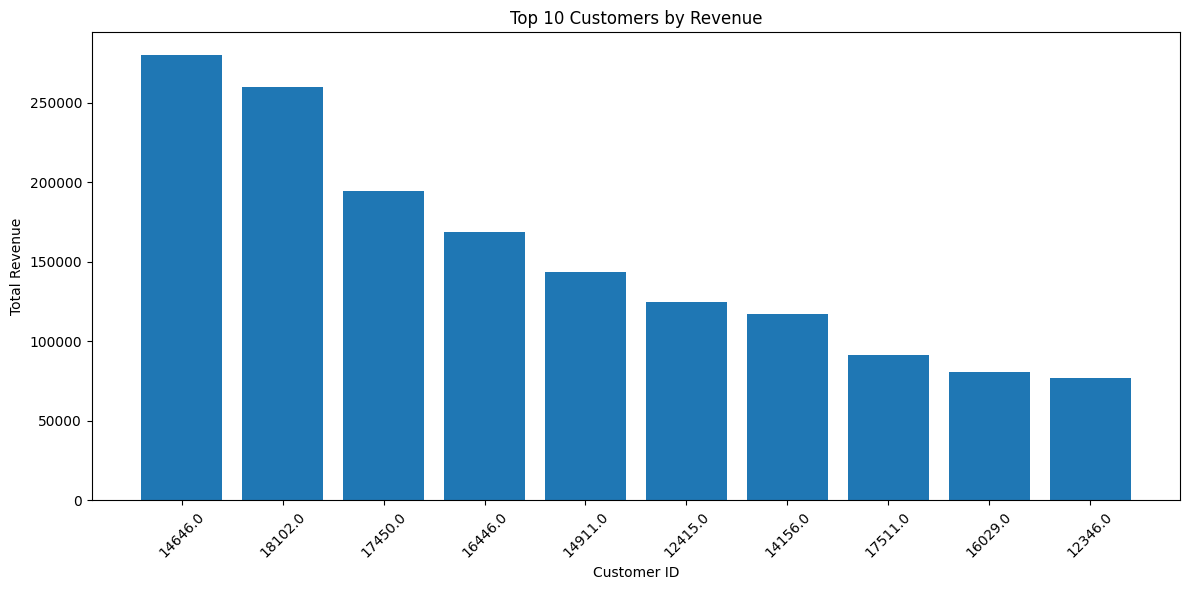

CUSTOMER PURCHASE FREQUENCY


,count
PurchaseCategory,
One-time,1493
2-5 Orders,1973
6-10 Orders,535
Above 10 Orders,337


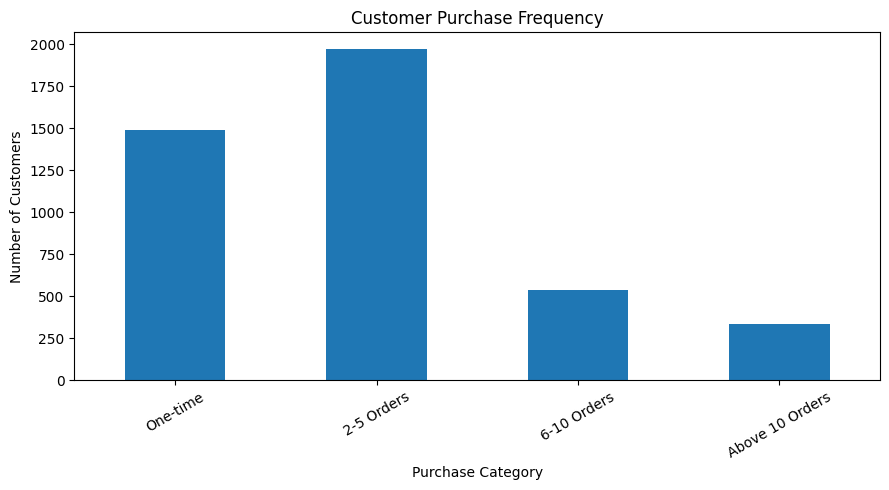

In [10]:
# Customer analysis
customer_df = sales_df.dropna(subset=["CustomerID"]).copy()

customer_summary = (
    customer_df.groupby("CustomerID")
    .agg(
        TotalRevenue=("TotalAmount", "sum"),
        TotalOrders=("InvoiceNo", "nunique"),
        TotalQuantity=("Quantity", "sum")
    )
    .reset_index()
)

customer_summary["AverageOrderValue"] = (
    customer_summary["TotalRevenue"] /
    customer_summary["TotalOrders"]
)

# Top 10 customers by revenue
top_customers = customer_summary.sort_values(
    "TotalRevenue", ascending=False
).head(10)

print("TOP 10 CUSTOMERS BY REVENUE")
display(top_customers.round(2))

# Visualization
plt.figure(figsize=(12, 6))

plt.bar(
    top_customers["CustomerID"].astype(str),
    top_customers["TotalRevenue"]
)

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Customer ID")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Customer purchase frequency
customer_summary["PurchaseCategory"] = pd.cut(
    customer_summary["TotalOrders"],
    bins=[0, 1, 5, 10, float("inf")],
    labels=["One-time", "2-5 Orders", "6-10 Orders", "Above 10 Orders"]
)

purchase_frequency = customer_summary[
    "PurchaseCategory"
].value_counts().sort_index()

print("CUSTOMER PURCHASE FREQUENCY")
display(purchase_frequency)

plt.figure(figsize=(9, 5))
purchase_frequency.plot(kind="bar")

plt.title("Customer Purchase Frequency")
plt.xlabel("Purchase Category")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

TRANSACTION TYPE ANALYSIS


,TransactionType,TotalRecords,UniqueInvoices,TotalQuantity,TotalAmount
0,Bad Debt Adjustment,3,3,3,-11062.06
1,Cancellation,9251,3836,-275560,-893979.73
2,Return,1336,1336,-206957,0.00
3,Sale,524877,19959,5572419,10631048.74
4,Zero Price,1174,819,72597,0.00


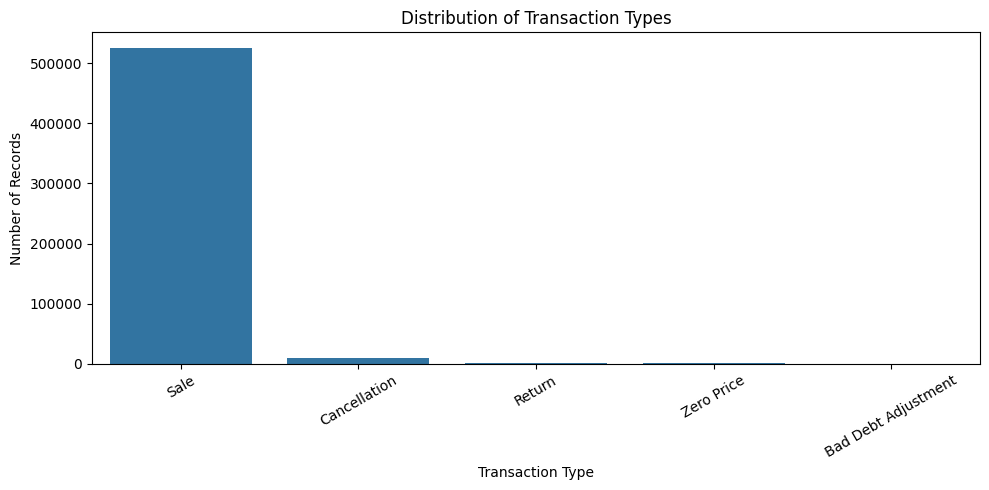

DATA QUALITY ANALYSIS


,count
DataQualityFlag,
Normal,535367
Zero Price - Review,1174
Unknown Description,97
Accounting Adjustment,3


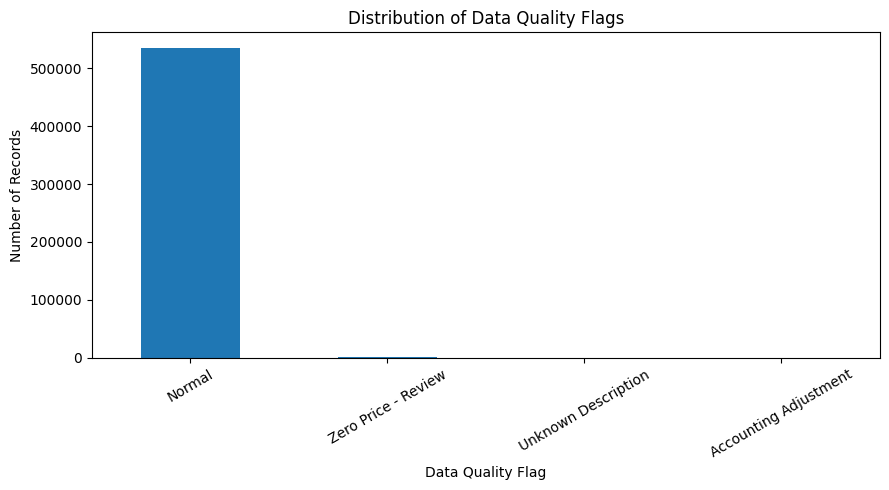

ANOMALY ANALYSIS
----------------------------------------
Negative quantities: 10587
Negative unit prices: 2
Zero quantities: 0
Zero unit prices: 2510
Negative total amounts: 9253
Zero total amounts: 2514


In [11]:
# Transaction type analysis

transaction_analysis = (
    df.groupby("TransactionType")
    .agg(
        TotalRecords=("InvoiceNo", "count"),
        UniqueInvoices=("InvoiceNo", "nunique"),
        TotalQuantity=("Quantity", "sum"),
        TotalAmount=("TotalAmount", "sum")
    )
    .reset_index()
)

print("TRANSACTION TYPE ANALYSIS")
display(transaction_analysis.round(2))

# Transaction type chart

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="TransactionType",
    order=df["TransactionType"].value_counts().index
)

plt.title("Distribution of Transaction Types")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Records")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# Data quality analysis

quality_analysis = df["DataQualityFlag"].value_counts()

print("DATA QUALITY ANALYSIS")
display(quality_analysis)

plt.figure(figsize=(9, 5))

quality_analysis.plot(kind="bar")

plt.title("Distribution of Data Quality Flags")
plt.xlabel("Data Quality Flag")
plt.ylabel("Number of Records")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# Investigate negative and zero values

print("ANOMALY ANALYSIS")
print("-" * 40)

print("Negative quantities:", (df["Quantity"] < 0).sum())
print("Negative unit prices:", (df["UnitPrice"] < 0).sum())
print("Zero quantities:", (df["Quantity"] == 0).sum())
print("Zero unit prices:", (df["UnitPrice"] == 0).sum())
print("Negative total amounts:", (df["TotalAmount"] < 0).sum())
print("Zero total amounts:", (df["TotalAmount"] == 0).sum())

In [12]:
# 1. Find the four Sale records excluded from sales_df

excluded_sales = df[
    (df["TransactionType"] == "Sale") &
    ~(
        (df["Quantity"] > 0) &
        (df["UnitPrice"] > 0) &
        (df["TotalAmount"] > 0)
    )
]

print("Sale records excluded by our filters:", len(excluded_sales))

display(excluded_sales[
    ["InvoiceNo", "StockCode", "Description",
     "Quantity", "UnitPrice", "TotalAmount", "DataQualityFlag"]
])


# 2. Inspect negative unit-price records

print("\nNEGATIVE UNIT PRICE RECORDS")

display(df[df["UnitPrice"] < 0][
    ["InvoiceNo", "StockCode", "Description",
     "Quantity", "UnitPrice", "TotalAmount", "TransactionType"]
])


# 3. Inspect return transactions

print("\nSAMPLE RETURN RECORDS")

display(df[df["TransactionType"] == "Return"][
    ["InvoiceNo", "StockCode", "Description",
     "Quantity", "UnitPrice", "TotalAmount"]
].head(10))


# 4. Compare zero-price classifications

print("\nZERO-PRICE CLASSIFICATION CHECK")

print("Zero UnitPrice but not classified as Zero Price:",
      len(df[(df["UnitPrice"] == 0) &
             (df["TransactionType"] != "Zero Price")]))

print("Classified as Zero Price but UnitPrice is nonzero:",
      len(df[(df["TransactionType"] == "Zero Price") &
             (df["UnitPrice"] != 0)]))


# 5. Compare transaction types with quality flags

print("\nTRANSACTION TYPE VS DATA QUALITY FLAG")

display(pd.crosstab(
    df["TransactionType"],
    df["DataQualityFlag"]
))

Sale records excluded by our filters: 4


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,TotalAmount,DataQualityFlag
155787,550193,PADS,PADS TO MATCH ALL CUSHIONS,1,0.001,0.0,Normal
276812,561226,PADS,PADS TO MATCH ALL CUSHIONS,1,0.001,0.0,Normal
357091,568200,PADS,PADS TO MATCH ALL CUSHIONS,1,0.001,0.0,Normal
358932,568375,BANK CHARGES,Bank Charges,1,0.001,0.0,Normal



NEGATIVE UNIT PRICE RECORDS


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,TotalAmount,TransactionType
297646,A563186,B,Adjust bad debt,1,-11062.06,-11062.06,Bad Debt Adjustment
297647,A563187,B,Adjust bad debt,1,-11062.06,-11062.06,Bad Debt Adjustment



SAMPLE RETURN RECORDS


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,TotalAmount
2362,536589,21777,RECIPE BOX WITH METAL HEART,-10,0.0,-0.0
4286,536764,84952C,MIRROR LOVE BIRD T-LIGHT HOLDER,-38,0.0,-0.0
7086,536996,22712,CARD DOLLY GIRL,-20,0.0,-0.0
7087,536997,22028,PENNY FARTHING BIRTHDAY CARD,-20,0.0,-0.0
7088,536998,85067,CREAM SWEETHEART WALL CABINET,-6,0.0,-0.0
7090,537000,21414,SCALLOP SHELL SOAP DISH,-22,0.0,-0.0
7091,537001,21653,Unknown,-6,0.0,-0.0
7093,537003,85126,LARGE ROUND CUTGLASS CANDLESTICK,-2,0.0,-0.0
7094,537004,21814,HEART T-LIGHT HOLDER,-30,0.0,-0.0
7095,537005,21692,SILVER LATTICE VANILLA CANDLE POT,-70,0.0,-0.0



ZERO-PRICE CLASSIFICATION CHECK
Zero UnitPrice but not classified as Zero Price: 1336
Classified as Zero Price but UnitPrice is nonzero: 0

TRANSACTION TYPE VS DATA QUALITY FLAG


DataQualityFlag,Accounting Adjustment,Normal,Unknown Description,Zero Price - Review
TransactionType,,,,
Bad Debt Adjustment,3,0,0,0
Cancellation,0,9251,0,0
Return,0,1239,97,0
Sale,0,524877,0,0
Zero Price,0,0,0,1174


In [14]:
# Corrected sales dataset
sales_df = df[
    (df["TransactionType"] == "Sale") &
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
].copy()

# Extract date features again
sales_df["InvoiceDate"] = pd.to_datetime(sales_df["InvoiceDate"])

sales_df["Year"] = sales_df["InvoiceDate"].dt.year
sales_df["Month"] = sales_df["InvoiceDate"].dt.month
sales_df["MonthName"] = sales_df["InvoiceDate"].dt.strftime("%b")
sales_df["DayName"] = sales_df["InvoiceDate"].dt.day_name()
sales_df["Hour"] = sales_df["InvoiceDate"].dt.hour

print("Corrected sales records:", len(sales_df))
print("Total quantity:", sales_df["Quantity"].sum())
print("Total revenue:", round(sales_df["TotalAmount"].sum(), 2))
print("Total orders:", sales_df["InvoiceNo"].nunique())

Corrected sales records: 524877
Total quantity: 5572419
Total revenue: 10631048.74
Total orders: 19959


WEEKDAY SALES ANALYSIS


,Revenue,Orders
DayName,,
Monday,1775782.07,3126.0
Tuesday,2175700.51,3554.0
Wednesday,1847074.38,3690.0
Thursday,2199292.57,4246.0
Friday,1826408.43,3139.0
Saturday,NaN,NaN
Sunday,806790.78,2204.0


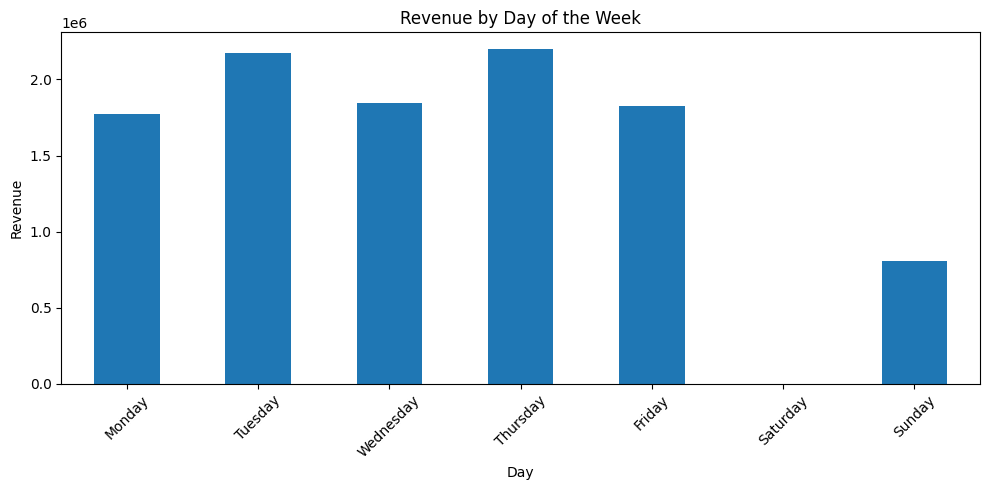

HOURLY SALES ANALYSIS


,Revenue,Orders
Hour,,
6,4.25,1
7,31059.21,29
8,283750.68,566
9,990054.99,1484
10,1444814.77,2361
11,1236573.29,2396
12,1439324.66,3220
13,1261195.20,2753
14,1166845.46,2456


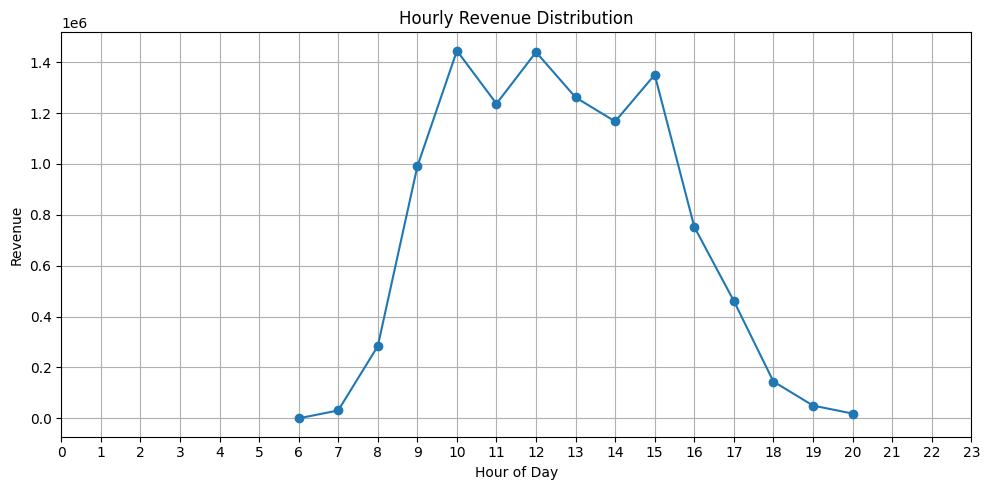

In [15]:
# Sales by weekday
weekday_analysis = (
    sales_df.groupby("DayName")
    .agg(
        Revenue=("TotalAmount", "sum"),
        Orders=("InvoiceNo", "nunique")
    )
)

weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_analysis = weekday_analysis.reindex(weekday_order)

print("WEEKDAY SALES ANALYSIS")
display(weekday_analysis.round(2))

# Weekday revenue chart
plt.figure(figsize=(10, 5))
weekday_analysis["Revenue"].plot(kind="bar")

plt.title("Revenue by Day of the Week")
plt.xlabel("Day")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# Hourly sales analysis
hourly_sales = (
    sales_df.groupby("Hour")
    .agg(
        Revenue=("TotalAmount", "sum"),
        Orders=("InvoiceNo", "nunique")
    )
)

print("HOURLY SALES ANALYSIS")
display(hourly_sales.round(2))

# Hourly revenue chart
plt.figure(figsize=(10, 5))
hourly_sales["Revenue"].plot(kind="line", marker="o")

plt.title("Hourly Revenue Distribution")
plt.xlabel("Hour of Day")
plt.ylabel("Revenue")
plt.xticks(range(0, 24))
plt.grid(True)
plt.tight_layout()
plt.show()

AVERAGE DAILY REVENUE BY WEEKDAY


,AverageDailyRevenue,DaysObserved
DayName,,
Monday,37782.60,47.0
Tuesday,41840.39,52.0
Wednesday,34850.46,53.0
Thursday,41496.09,53.0
Friday,36528.17,50.0
Saturday,NaN,NaN
Sunday,16135.82,50.0


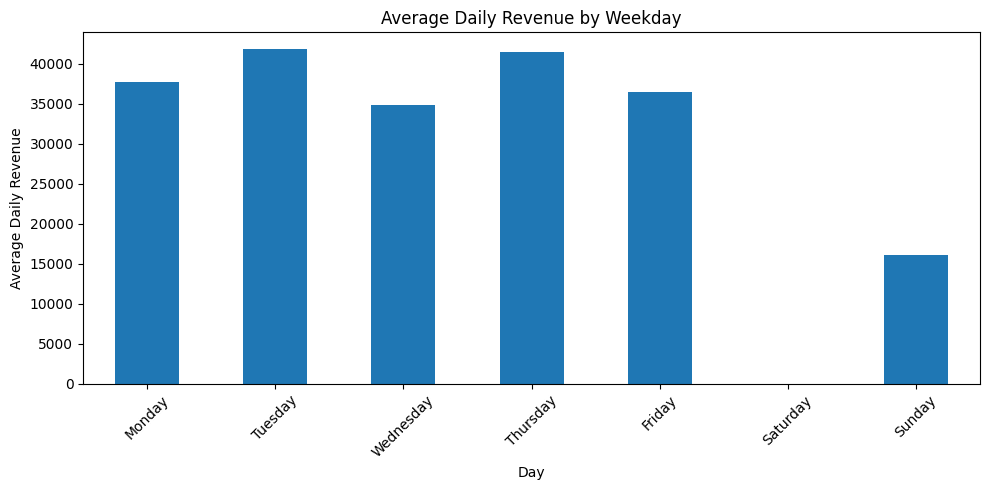

In [16]:
# Average daily revenue by weekday

daily_revenue = (
    sales_df.groupby(sales_df["InvoiceDate"].dt.date)["TotalAmount"]
    .sum()
    .reset_index(name="DailyRevenue")
)

daily_revenue["DayName"] = pd.to_datetime(
    daily_revenue["InvoiceDate"]
).dt.day_name()

avg_weekday_revenue = (
    daily_revenue.groupby("DayName")
    .agg(
        AverageDailyRevenue=("DailyRevenue", "mean"),
        DaysObserved=("DailyRevenue", "count")
    )
    .reindex(weekday_order)
)

print("AVERAGE DAILY REVENUE BY WEEKDAY")
display(avg_weekday_revenue.round(2))

plt.figure(figsize=(10, 5))
avg_weekday_revenue["AverageDailyRevenue"].plot(kind="bar")

plt.title("Average Daily Revenue by Weekday")
plt.xlabel("Day")
plt.ylabel("Average Daily Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Key Business Insights

1. **Monthly Sales Performance:** November 2011 recorded the highest monthly revenue of 1,503,866.78. Revenue increased significantly from September to November.

2. **Product Performance:** PAPER CRAFT, LITTLE BIRDIE recorded the highest quantity sold at 80,995 units in a single order. This highlights the presence of large bulk transactions.

3. **Geographical Performance:** The United Kingdom contributed approximately 84.57% of total sales revenue, making it the dominant market.

4. **Customer Purchasing Behaviour:** Approximately 65.58% of identified customers made repeat purchases, while 34.42% purchased only once.

5. **Transaction Analysis:** The dataset contained 9,251 cancellation records with a combined negative transaction amount of 893,979.73. Returns and zero-price transactions also require separate treatment.

6. **Weekday Sales Trends:** Thursday recorded the highest total weekday revenue of 2,199,292.57.

7. **Hourly Sales Trends:** 10 AM recorded the highest hourly revenue, while 12 PM recorded the highest number of orders.

8. **Average Daily Revenue:** Tuesday had the highest average daily revenue of 41,840.39, slightly higher than Thursday.

# Conclusion

The exploratory data analysis revealed important patterns in sales performance, customer purchasing behaviour, product demand and geographical revenue distribution.

The analysis identified November as the strongest sales month and the United Kingdom as the primary revenue-generating market. Customer analysis showed that repeat purchases contributed to a significant portion of customer activity.

The analysis also highlighted unusual bulk transactions, cancellations, returns and zero-price records that require careful interpretation.

These findings can help businesses understand sales patterns, identify important markets, improve customer retention and make more informed business decisions.

# Limitations

- Approximately 25.16% of records have missing CustomerID values, limiting customer-level analysis.
- December 2011 contains only partial-month data.
- Saturday has no observed sales records.
- Return transactions have zero recorded unit prices and monetary amounts, limiting refund analysis.
- Large bulk transactions may influence product and customer rankings.

